In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

In [2]:
#loading data 

data = pd.read_csv('SOCR-HeightWeight.csv').set_index('Index')
data.head(5)
data.columns

Index(['Height(Inches)', 'Weight(Pounds)'], dtype='object')

In [3]:
#calculating mean
data.mean()

Height(Inches)     67.993114
Weight(Pounds)    127.079421
dtype: float64

In [4]:
#calculating std
data.std()

Height(Inches)     1.901679
Weight(Pounds)    11.660898
dtype: float64

Text(0.5, 0, 'Height(Inches)')

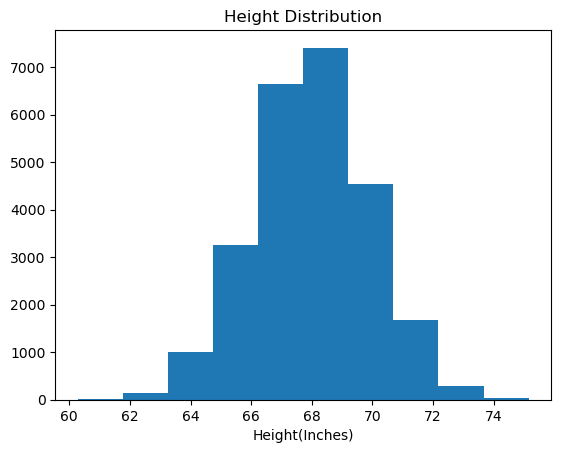

In [5]:
plt.hist(data['Height(Inches)'])
plt.title('Height Distribution')
plt.xlabel('Height(Inches)' )

Text(0.5, 0, 'Weight(Pounds)')

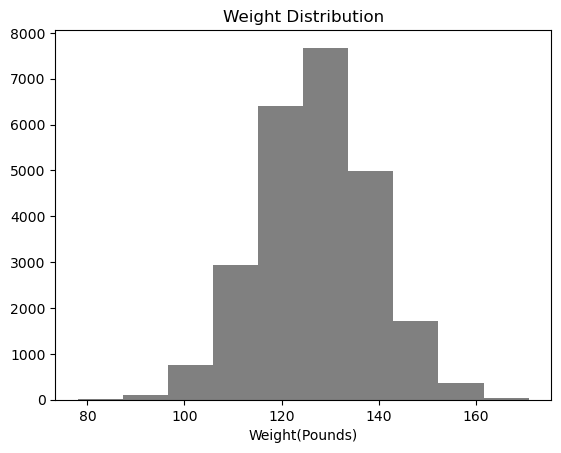

In [6]:
plt.hist(data['Weight(Pounds)'], color='gray')
plt.title('Weight Distribution')
plt.xlabel('Weight(Pounds)' )

$
r = \frac{\sum\left(x_{i}-\bar{x}\right)\left(y_{i}-\bar{y}\right)}{\sqrt{\sum\left(x_{i}-\bar{x}\right)^{2} \sum\left(y_{i}-\bar{y}\right)^{2}}}
$

In [7]:
#Compute the correlation between height and weight

# let height be x and weight be y
my_x = np.array(data['Height(Inches)'])
my_y = np.array(data['Weight(Pounds)'])

# a function to compute correlation between x and y
def correlation_function(x,y):
    x_bar = np.mean(my_x)
    y_bar = np.mean(my_y)
    numerator = np.sum((my_x - x_bar)*(my_y - y_bar))
    denominator = np.sqrt((np.sum((my_x - x_bar)**2)) * (np.sum((my_y - y_bar)**2)))
    r = numerator/denominator
    return r
 

In [8]:
correlation_function(my_x, my_y)

0.5028585206028441

In [9]:
np.corrcoef(my_x,my_y)

array([[1.        , 0.50285852],
       [0.50285852, 1.        ]])

In [10]:
# creating two lists from the data given
#let x be Time (hours) data and y be Bacteria Count
x = np.arange(0, 6)
y = np.array([100, 180, 324, 583.2, 1049.76, 1889.57], dtype=float)

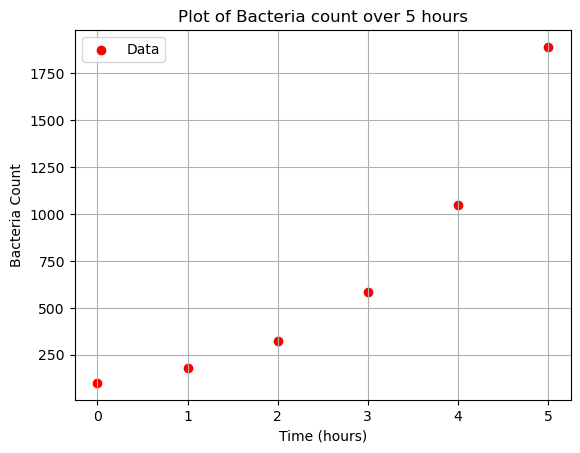

In [11]:
#visualising how our data is scattered 
plt.scatter(x,y, label= 'Data', c='r')
plt.xlabel('Time (hours)')
plt.ylabel('Bacteria Count')
plt.title('Plot of Bacteria count over 5 hours')
plt.legend()
plt.grid()

In [12]:
def exponential_growth(t, a,b):
    return a * np.exp(b * t)

def logistic_growth(t, K, A, B):
    return K / (1 + A * np.exp(-B * t))

def power_law(a,b,t):
    return a * (t ** b)

In [13]:
# initializing Parameters
a = 2  # example value for a
b = 0.5  # example value for b
t = x
K = 10  # Carrying capacity

In [14]:
y_exponent = exponential_growth(a,b,t)
y_logistic = logistic_growth(t,K,a,b)
y_power = power_law(a,b,t)

Text(0.5, 1.0, 'Power Growth')

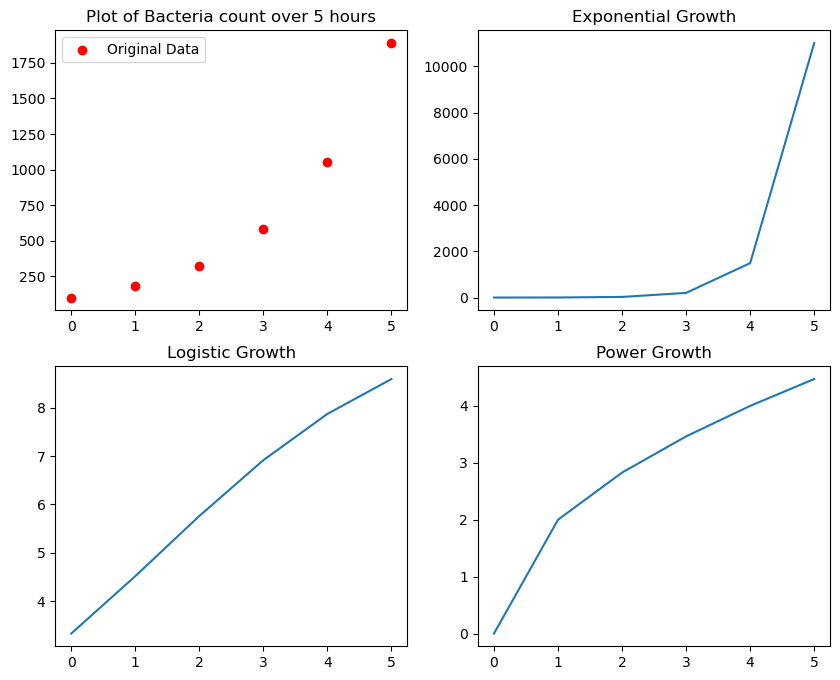

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0, 0].scatter(x,y, label= 'Original Data', c='r')
axes[0, 0].set_title('Plot of Bacteria count over 5 hours')
axes[0, 0].legend()

axes[0, 1].plot(x, y_exponent)
axes[0, 1].set_title('Exponential Growth')

axes[1, 0].plot(x, y_logistic)
axes[1, 0].set_title('Logistic Growth')

axes[1, 1].plot(x, y_power)
axes[1, 1].set_title('Power Growth')


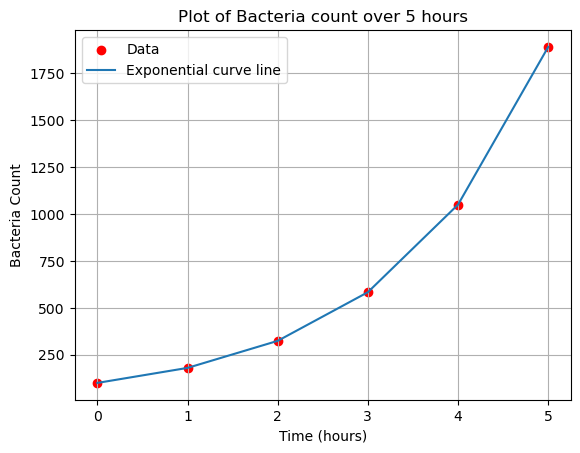

In [16]:
# creating two lists from the data given

# Fit the exponential curve to the data
popt, pcov = curve_fit(exponential_growth, x, y)
a_opt, b_opt = popt  # Fitted parameters a and b

# Generate the y values using the fitted curve
y_curve = exponential_growth(x, *popt)


plt.scatter(x,y, label= 'Data', color='r')
plt.plot(x,y_curve, label="Exponential curve line")  
plt.xlabel('Time (hours)')
plt.ylabel('Bacteria Count')
plt.title('Plot of Bacteria count over 5 hours')
plt.legend()
plt.grid()

In [17]:
# Compute the residuals
residuals = y - y_curve

# Compute SS_res (sum of squared residuals)
ss_res = np.sum(residuals**2)

# Compute SS_tot (total sum of squares)
ss_tot = np.sum((y - np.mean(y))**2)

# Compute R^2
r_squared = 1 - (ss_res / ss_tot)

print(f"Coefficient of Determination (R^2): {r_squared:.4f}")

Coefficient of Determination (R^2): 1.0000


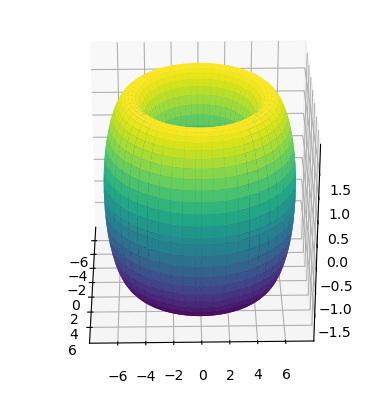

In [119]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation

# Parametric equations
def x_function(u, v):
    return (R + r*np.cos(v)) * np.cos(u)

def y_function(u, v):
    return (R + r*np.cos(v)) * np.sin(u)

def z_function(u, v):
    return r * np.sin(v)

# Parameters
R = 5  # Major radius
r = 2  # Minor radius
pi = np.pi
u = np.linspace(0, 2*pi, 100)
v = np.linspace(0, 2*pi, 100)

# Create a meshgrid for u, v
u, v = np.meshgrid(u, v)

# Compute x, y, z coordinates
x = x_function(u, v)
y = y_function(u, v)
z = z_function(u, v)

# Plotting
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Surface plot
ax.plot_surface(x, y, z, cmap='viridis')

# Set an equal aspect ratio
ax.set_box_aspect([1,1,1])  # Aspect ratio 1:1:1


# Define animation function
def update(frame):
    ax.view_init(elev=30, azim=frame)
    return fig,

# Create animation
ani = FuncAnimation(fig, update, frames=np.arange(0, 360, 1), interval=50)

# Save animation as a gif
ani.save('rotating_surface_plot.gif', writer='pillow')

plt.show()


In [19]:
#Exploratory Analysis on Real-World Data
#Load the dataset using pandas and display all necessary information contained in the file

df = pd.read_csv('task1.txt')
df.head(5)

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2008,1,1,2,120.0,1935,309.0,2130,9E,5746,...,3.0,18.0,0,NaN,0,339.0,0.0,0.0,0.0,0.0
1,2008,1,1,2,555.0,600,826.0,835,AA,1614,...,7.0,11.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
2,2008,1,1,2,600.0,600,728.0,729,YV,2883,...,7.0,16.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
3,2008,1,1,2,601.0,605,727.0,750,9E,5743,...,4.0,12.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
4,2008,1,1,2,601.0,600,654.0,700,AA,1157,...,5.0,10.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN


In [20]:
df.isnull().sum()

Year                     0
Month                    0
DayofMonth               0
DayOfWeek                0
DepTime               1413
CRSDepTime               0
ArrTime               1567
CRSArrTime               0
UniqueCarrier            0
FlightNum                0
TailNum               1104
ActualElapsedTime     1601
CRSElapsedTime          11
AirTime               1601
ArrDelay              1601
DepDelay              1413
Origin                   0
Dest                     0
Distance                 0
TaxiIn                1567
TaxiOut               1419
Cancelled                0
CancellationCode     97840
Diverted                 0
CarrierDelay         79513
WeatherDelay         79513
NASDelay             79513
SecurityDelay        79513
LateAircraftDelay    79513
dtype: int64

In [21]:
df.columns

Index(['Year', 'Month', 'DayofMonth', 'DayOfWeek', 'DepTime', 'CRSDepTime',
       'ArrTime', 'CRSArrTime', 'UniqueCarrier', 'FlightNum', 'TailNum',
       'ActualElapsedTime', 'CRSElapsedTime', 'AirTime', 'ArrDelay',
       'DepDelay', 'Origin', 'Dest', 'Distance', 'TaxiIn', 'TaxiOut',
       'Cancelled', 'CancellationCode', 'Diverted', 'CarrierDelay',
       'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay'],
      dtype='object')

In [22]:
df['total_delay'] = df[['DepDelay', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay']].sum(axis=1)
df

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,total_delay
0,2008,1,1,2,120.0,1935,309.0,2130,9E,5746,...,18.0,0,NaN,0,339.0,0.0,0.0,0.0,0.0,684.0
1,2008,1,1,2,555.0,600,826.0,835,AA,1614,...,11.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,-5.0
2,2008,1,1,2,600.0,600,728.0,729,YV,2883,...,16.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,0.0
3,2008,1,1,2,601.0,605,727.0,750,9E,5743,...,12.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,-4.0
4,2008,1,1,2,601.0,600,654.0,700,AA,1157,...,10.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99255,2008,12,31,3,2109.0,2100,2158.0,2157,CO,1533,...,18.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,9.0
99256,2008,12,31,3,2124.0,2123,2246.0,2300,9E,5805,...,22.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,1.0
99257,2008,12,31,3,2327.0,2325,9.0,20,AA,1532,...,7.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN,2.0
99258,2008,12,31,3,NaN,1220,NaN,1711,B6,1264,...,NaN,1,B,0,NaN,NaN,NaN,NaN,NaN,0.0


In [25]:
# time of the day, possible delays, change with airlines
#'DayOfWeek'vs 'DepDelay' later we do 'DayOfWeek' vs 'CarrierDelay' 
austin_region = df[df['Dest'] == 'AUS']

general_daily_delay = austin_region[['DayOfWeek','total_delay']].groupby('DayOfWeek').sum()
carrier_daily_delay = austin_region[['UniqueCarrier','total_delay']].groupby('UniqueCarrier').sum()


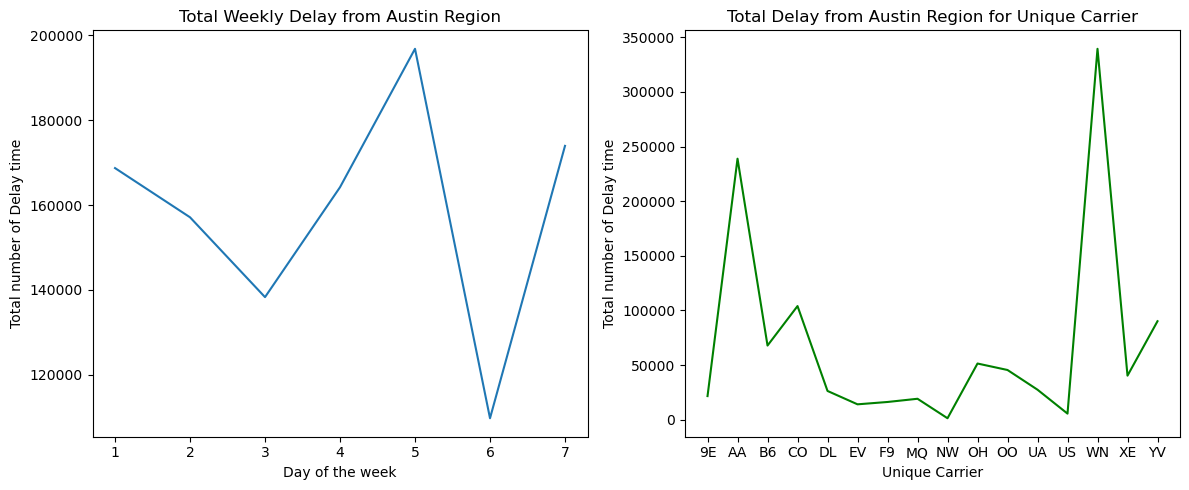

In [27]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(general_daily_delay['total_delay'])
ax1.set_title('Total Weekly Delay from Austin Region')
ax1.set_xlabel("Day of the week")
ax1.set_ylabel("Total number of Delay time")

ax2.plot(carrier_daily_delay['total_delay'], c='g')
ax2.set_title('Total Delay from Austin Region for Unique Carrier')
ax2.set_xlabel("Unique Carrier")
ax2.set_ylabel("Total number of Delay time")

# Adjust layout to prevent overlap
plt.tight_layout()

In [28]:
#Investigate what time of the year it is more suited to fly so as to have the delays minimum and
#does the destination affect this? You can lay insights on some popular destinations for the task.

general_monthly_delay = df[['Month','total_delay']].groupby('Month').sum()
austin_monthly_delay = austin_region[['Month','total_delay' ]].groupby('Month').sum()
PHX_region = df[df['Dest'] == 'PHX']
PHX_monthly_delay = PHX_region[['Month','total_delay' ]].groupby('Month').sum()
BOS_region = df[df['Dest'] == 'BOS']
BOS_monthly_delay = BOS_region[['Month','total_delay' ]].groupby('Month').sum()


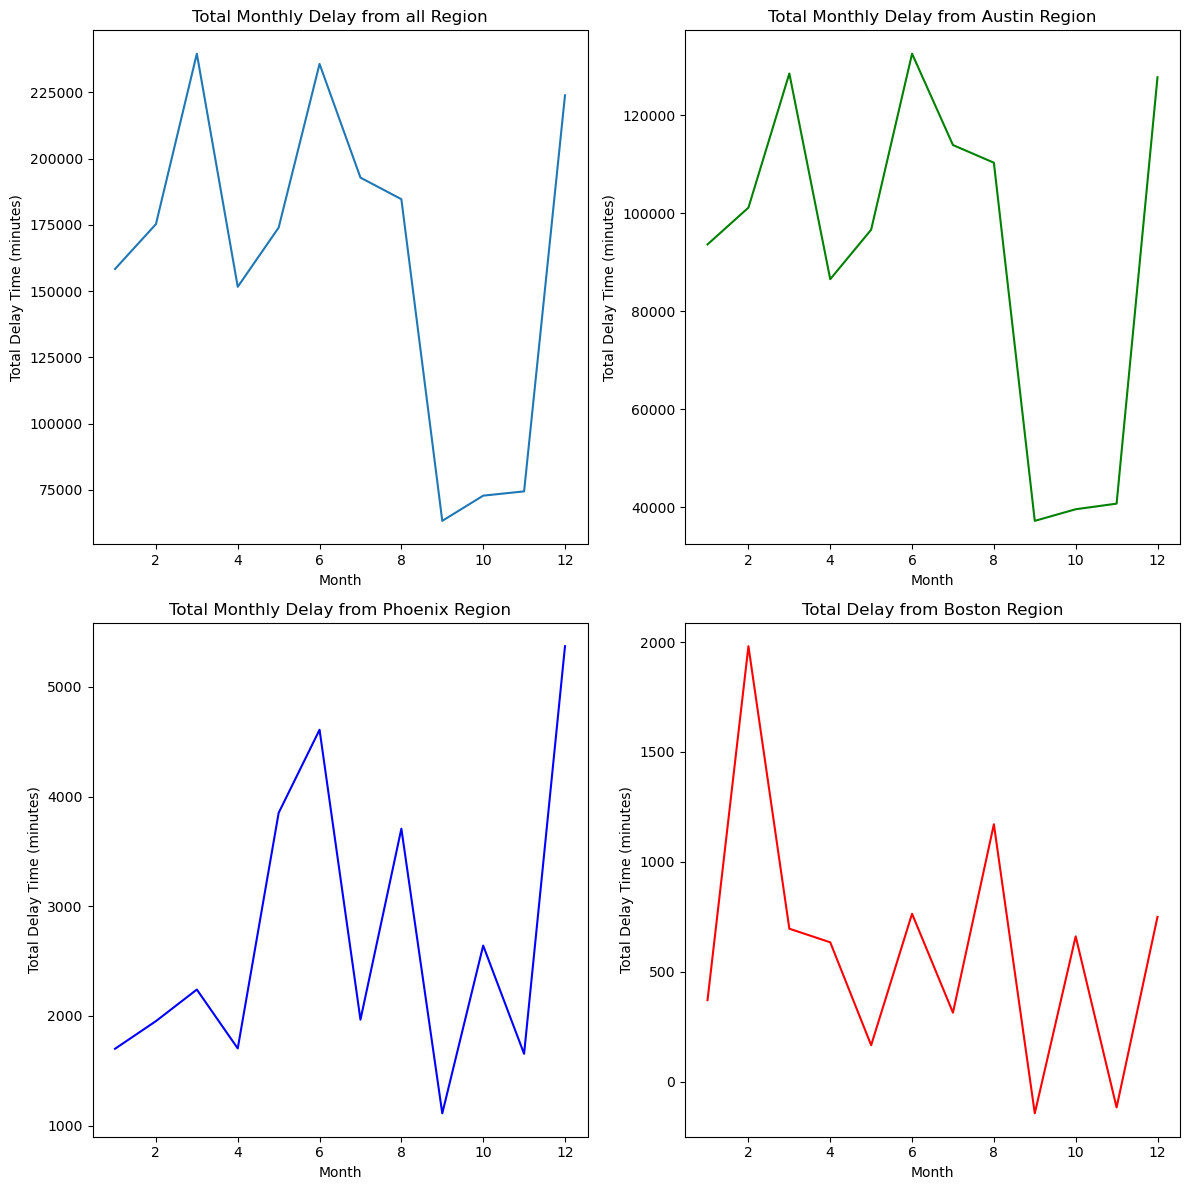

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# Flatten the 2D array of axes for easier indexing
(ax1, ax2), (ax3, ax4) = axes

# Plot total weekly delay from Austin region
ax1.plot(general_monthly_delay['total_delay'])
ax1.set_title('Total Monthly Delay from all Region')
ax1.set_xlabel("Month")
ax1.set_ylabel("Total Delay Time (minutes)")

# Plot total delay from Austin region for a unique carrier
ax2.plot(austin_monthly_delay['total_delay'], c='g')
ax2.set_title('Total Monthly Delay from Austin Region')
ax2.set_xlabel("Month")
ax2.set_ylabel("Total Delay Time (minutes)")

# Plot total delay from Austin region to Phoenix
ax3.plot(PHX_monthly_delay['total_delay'], c='b')
ax3.set_title('Total Monthly Delay from Phoenix Region')
ax3.set_xlabel("Month")
ax3.set_ylabel("Total Delay Time (minutes)")

# Plot total delay from Austin region to Boston
ax4.plot(BOS_monthly_delay['total_delay'], c='r')
ax4.set_title('Total Delay from Boston Region')
ax4.set_xlabel("Month")
ax4.set_ylabel("Total Delay Time (minutes)")

# Adjust layout to prevent overlap
plt.tight_layout()

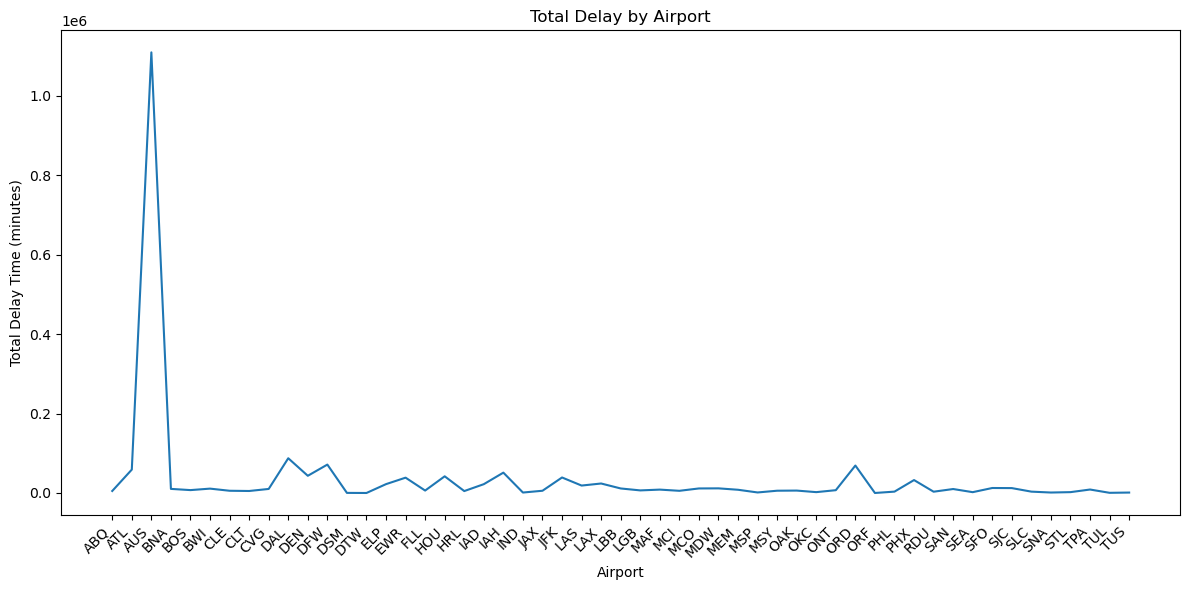

In [30]:
airport_delay = df[['Dest', 'total_delay']].groupby('Dest').sum()
# Create a plot with the specified figure size
plt.figure(figsize=(12, 6))

# Plot the total delay
plt.plot(airport_delay['total_delay'])

# Set title and labels
plt.title('Total Delay by Airport')
plt.xlabel("Airport")
plt.ylabel("Total Delay Time (minutes)")

# Rotate x-axis labels to make airport names visible
plt.xticks(ticks=range(len(airport_delay.index)), labels=airport_delay.index, rotation=45, ha='right')

# Adjust layout to prevent overlap
plt.tight_layout()


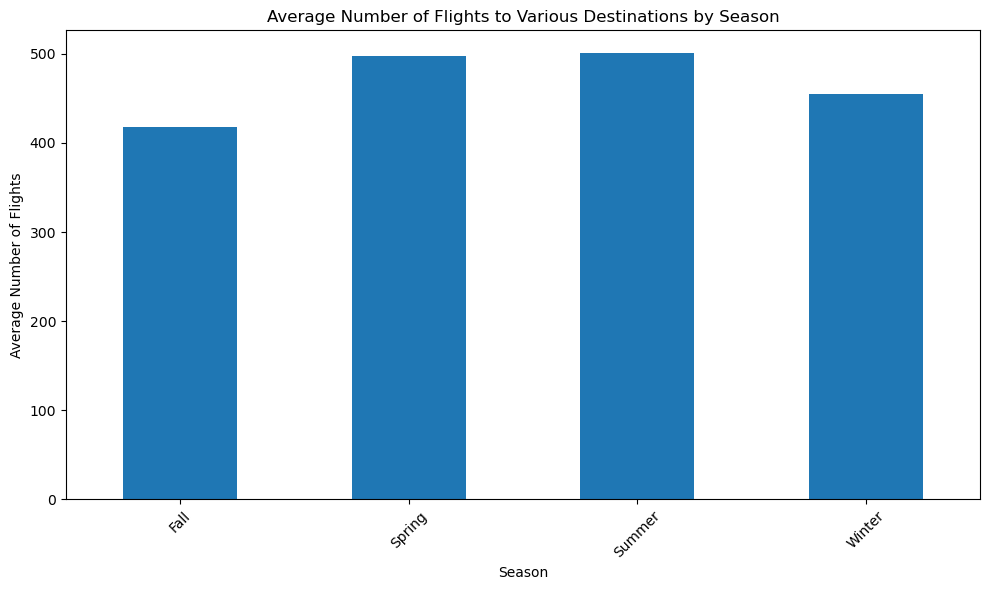

In [33]:
# Define seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'
    
# Create a new column for seasons
df['Season'] = df['Month'].apply(get_season)

# Count flights by season and destination
seasonal_flight_counts = df.groupby(['Season', 'Dest']).size().unstack(fill_value=0)

# Calculate the average number of flights per destination for each season
seasonal_average = seasonal_flight_counts.mean(axis=1)

# Create a bar plot for average flights by season
plt.figure(figsize=(10, 6))
seasonal_average.plot(kind='bar')

# Set title and labels
plt.title('Average Number of Flights to Various Destinations by Season')
plt.xlabel('Season')
plt.ylabel('Average Number of Flights')
plt.xticks(rotation=45)

# Show the plot
plt.tight_layout()
plt.show()

In [68]:
sport_data = pd.read_csv('task2.txt')
sport_data.head(5)

,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal
0,16,Juhamatti Tapio Aaltonen,M,28,184,85.0,Finland,FIN,2014 Winter,2014,Winter,Sochi,Ice Hockey,Ice Hockey Men's Ice Hockey,Bronze
1,17,Paavo Johannes Aaltonen,M,28,175,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Individual All-Around,Bronze
2,17,Paavo Johannes Aaltonen,M,28,175,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Team All-Around,Gold
3,17,Paavo Johannes Aaltonen,M,28,175,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Horse Vault,Gold
4,17,Paavo Johannes Aaltonen,M,28,175,64.0,Finland,FIN,1948 Summer,1948,Summer,London,Gymnastics,Gymnastics Men's Pommelled Horse,Gold


In [70]:
female_athletics_data = sport_data[
    (sport_data['sport'] == 'Athletics') &
    (sport_data['sex'] == 'F') &
    (sport_data['event']== "Athletics Women's 100 metres")]

height_95th_percentile = female_athletics_data["height"].quantile(0.95)
print(f"95th percentile of heights for female Athletics competitors: {height_95th_percentile} cm")


95th percentile of heights for female Athletics competitors: 179.6 cm


In [91]:
#Find the single woman’s event that depicts the highest variability in the height of the competitor
#across the entire history of Olympics. Use the standard deviation as the yardstick for this.
female_events = sport_data[sport_data['sex'] == 'F'] 
female_events_std_dev = female_events[['event', 'height']].groupby('event').std()
event_with_highest_std_dev = female_events_std_dev.idxmax()
print(event_with_highest_std_dev[0])

Rowing Women's Coxed Fours


In [115]:
#'age','sex','year'sport
#average age of swimmers
swimmer_data = sport_data[sport_data['sport'] == "Swimming"]
average_age_by_year_gender = swimmer_data.groupby(["year", "sex"])["age"].mean().unstack()

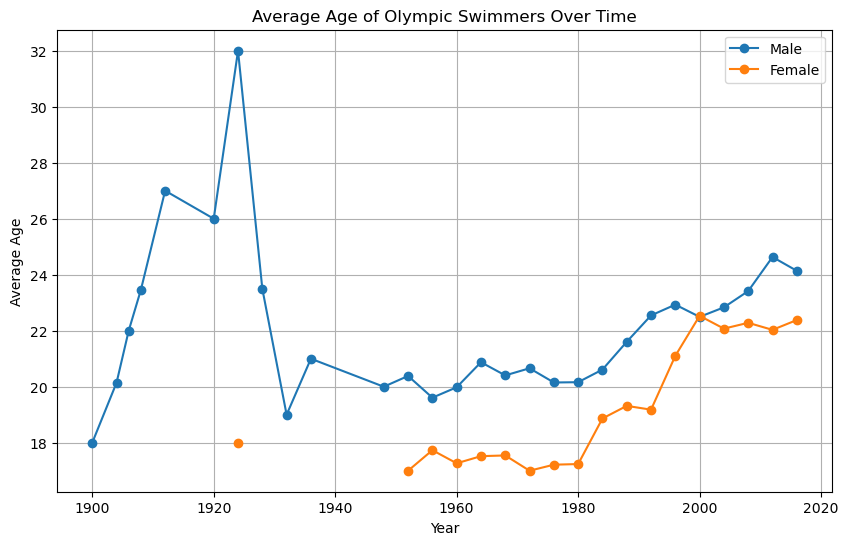

In [114]:

plt.figure(figsize=(10, 6))
plt.plot(average_age_by_year_gender.index, average_age_by_year_gender["M"], label="Male", marker='o')
plt.plot(average_age_by_year_gender.index, average_age_by_year_gender["F"], label="Female", marker='o')

plt.xlabel("Year")
plt.ylabel("Average Age")
plt.title("Average Age of Olympic Swimmers Over Time")
plt.legend()
plt.grid(True)

plt.show()